# 01 — Exploration du Dataset CICIDS2017

**Projet :** NIDS-FL (Network Intrusion Detection System — Federated Learning)
**Dataset :** CICIDS2017 nettoyé — ericanacletoribeiro/cicids2017-cleaned-and-preprocessed
**Objectif :** Valider les 11 features sélectionnées par benchmark, comprendre la distribution
des classes, et préparer la configuration preprocessing pour l'AutoEncoder FL.

> Toutes les figures sont sauvegardées dans `docs/images/eda_*.png`.


---
## 1. Imports & Chargement des données

Le dataset (685 MB, 2,5 M lignes) est chargé **en chunks** pour éviter les pics mémoire,
puis concaténé en un seul DataFrame en ne retenant que les colonnes utiles.


In [4]:
from __future__ import annotations

import json
import os
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")

# ── Plotly optionnel (pas bloquant si absent) ──
try:
    import plotly.express as px
    import plotly.graph_objects as go
    from plotly.subplots import make_subplots
    HAS_PLOTLY = True
except ImportError:
    HAS_PLOTLY = False
    print("plotly absent — les cellules Plotly seront ignorées")

# ── Chemins ──
PROJECT_ROOT = Path().resolve().parent if Path().resolve().name == "notebooks" else Path().resolve()
DATA_DIR   = PROJECT_ROOT / "data"
DOCS_IMAGES = PROJECT_ROOT / "docs" / "images"
DOCS_IMAGES.mkdir(parents=True, exist_ok=True)

# ── Style global ──
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({"figure.dpi": 120, "axes.titlesize": 13, "axes.labelsize": 11})

PALETTE = {
    "Normal Traffic": "#4472C4",
    "DoS":            "#FF4B4B",
    "DDoS":           "#FF8C00",
    "Port Scanning":  "#FFC107",
    "Brute Force":    "#9C27B0",
    "Web Attacks":    "#E91E63",
    "Bots":           "#00BCD4",
}
ATTACK_ORDER = ["Normal Traffic","DoS","DDoS","Port Scanning","Brute Force","Web Attacks","Bots"]

print(f"PROJECT_ROOT : {PROJECT_ROOT}")
print(f"DATA_DIR     : {DATA_DIR}")
print(f"DOCS_IMAGES  : {DOCS_IMAGES}")


PROJECT_ROOT : /home/hamza/nids-fl-project
DATA_DIR     : /home/hamza/nids-fl-project/data
DOCS_IMAGES  : /home/hamza/nids-fl-project/docs/images


In [5]:
# ── Détection automatique des CSV ──
csv_files: list[Path] = sorted(DATA_DIR.glob("*.csv"))
print(f"{len(csv_files)} fichier(s) CSV détecté(s) :")
for f in csv_files:
    size_mb = f.stat().st_size / 1_048_576
    print(f"  {f.name:<50} {size_mb:>7.1f} MB")


1 fichier(s) CSV détecté(s) :
  cicids2017_cleaned.csv                               684.0 MB


In [6]:
# ── 11 features validées + label ──
FEATURES_11: list[str] = [
    "Average Packet Size",
    "Subflow Fwd Bytes",
    "Destination Port",
    "Init_Win_bytes_forward",
    "PSH Flag Count",
    "FIN Flag Count",
    "ACK Flag Count",
    "Flow Bytes/s",
    "Flow Packets/s",
    "Fwd Packets/s",
    "Total Fwd Packets",
]
LABEL_COL = "Attack Type"
CHUNK_SIZE = 300_000          # lignes par chunk

# ── Chargement en chunks ──
frames: list[pd.DataFrame] = []
total_raw = 0

for csv_path in csv_files:
    for chunk in pd.read_csv(csv_path, chunksize=CHUNK_SIZE, low_memory=False):
        chunk.columns = chunk.columns.str.strip()
        total_raw += len(chunk)
        # Ne garder que les colonnes utiles
        keep = [c for c in FEATURES_11 + [LABEL_COL] if c in chunk.columns]
        frames.append(chunk[keep])

df = pd.concat(frames, ignore_index=True)
df[LABEL_COL] = df[LABEL_COL].str.strip()

# Vérifier que les colonnes existent
missing_cols = [f for f in FEATURES_11 if f not in df.columns]
if missing_cols:
    print(f"⚠️  Colonnes manquantes : {missing_cols}")
else:
    print(f"✅ Les 11 features sont toutes présentes")

print(f"\nLignes totales chargées : {len(df):,}")
print(f"Colonnes retenues        : {len(df.columns)}")
print(f"Mémoire DataFrame        : {df.memory_usage(deep=True).sum() / 1_048_576:.1f} MB")


✅ Les 11 features sont toutes présentes

Lignes totales chargées : 2,520,751
Colonnes retenues        : 12
Mémoire DataFrame        : 359.6 MB


In [7]:
df.head(5)


,Average Packet Size,Subflow Fwd Bytes,Destination Port,Init_Win_bytes_forward,PSH Flag Count,FIN Flag Count,ACK Flag Count,Flow Bytes/s,Flow Packets/s,Fwd Packets/s,Total Fwd Packets,Attack Type
0,113.152941,2664,22,29200,1,0,0,7595.104640,67.122468,32.376720,41,Normal Traffic
1,113.152941,2664,22,29200,1,0,0,7289.936810,64.425518,31.075838,41,Normal Traffic
2,0.000000,0,22,290,0,0,1,0.000000,12500.000000,6250.000000,1,Normal Traffic
3,112.795181,2728,22,29200,1,0,0,7182.267884,63.675308,31.454068,41,Normal Traffic
4,0.000000,0,35396,243,0,0,1,0.000000,38961.038960,12987.012990,1,Normal Traffic


In [8]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2520751 entries, 0 to 2520750
Data columns (total 12 columns):
 #   Column                  Dtype  
---  ------                  -----  
 0   Average Packet Size     float64
 1   Subflow Fwd Bytes       int64  
 2   Destination Port        int64  
 3   Init_Win_bytes_forward  int64  
 4   PSH Flag Count          int64  
 5   FIN Flag Count          int64  
 6   ACK Flag Count          int64  
 7   Flow Bytes/s            float64
 8   Flow Packets/s          float64
 9   Fwd Packets/s           float64
 10  Total Fwd Packets       int64  
 11  Attack Type             object 
dtypes: float64(4), int64(7), object(1)
memory usage: 230.8+ MB


In [9]:
df[FEATURES_11].describe().round(3).T


,count,mean,std,min,25%,50%,75%,max
Average Packet Size,2520751.0,212.430,3.454930e+02,0.0,9.000,81.000,179.906,3.893333e+03
Subflow Fwd Bytes,2520751.0,606.513,1.010095e+04,0.0,12.000,66.000,332.000,1.287034e+07
Destination Port,2520751.0,8690.744,1.901294e+04,0.0,53.000,80.000,443.000,6.553500e+04
Init_Win_bytes_forward,2520751.0,7265.707,1.459806e+04,-1.0,-1.000,251.000,8192.000,6.553500e+04
PSH Flag Count,2520751.0,0.298,4.570000e-01,0.0,0.000,0.000,1.000,1.000000e+00
FIN Flag Count,2520751.0,0.032,1.760000e-01,0.0,0.000,0.000,0.000,1.000000e+00
ACK Flag Count,2520751.0,0.312,4.630000e-01,0.0,0.000,0.000,1.000,1.000000e+00
Flow Bytes/s,2520751.0,1410732.678,2.657109e+07,-261000000.0,119.431,3715.049,107142.857,2.071000e+09
Flow Packets/s,2520751.0,47292.725,2.026384e+05,-2000000.0,2.024,69.750,17857.143,4.000000e+06
Fwd Packets/s,2520751.0,40860.410,1.932673e+05,0.0,1.218,38.035,9433.962,3.000000e+06


---
## 2. Distribution des classes

CICIDS2017 est **fortement déséquilibré** : le trafic normal représente ~83 % des échantillons.
Ce déséquilibre a des implications directes sur le choix du modèle et des métriques :

- Un **AutoEncoder non-supervisé** entraîné uniquement sur le trafic normal contourne
  le problème de déséquilibre (pas de labels nécessaires).
- Les métriques pertinentes sont **F1-macro** et **AUC-ROC** plutôt que l'accuracy brute.


In [10]:
# Distribution des classes
class_dist = df[LABEL_COL].value_counts()
class_pct  = class_dist / len(df) * 100

print(f"{'Classe':<25} {'Count':>10}  {'%':>7}")
print("─" * 46)
for cls in ATTACK_ORDER:
    if cls in class_dist.index:
        print(f"{cls:<25} {class_dist[cls]:>10,}  {class_pct[cls]:>6.2f}%")

normal_pct = class_pct.get("Normal Traffic", 0)
attack_pct = 100 - normal_pct
print(f"\nRatio déséquilibre : Normal={normal_pct:.1f}%  Attaques={attack_pct:.1f}%")
print(f"Facteur : 1 attaque pour {normal_pct/attack_pct:.1f} paquets normaux")


Classe                         Count        %
──────────────────────────────────────────────
Normal Traffic             2,095,057   83.11%
DoS                          193,745    7.69%
DDoS                         128,014    5.08%
Port Scanning                 90,694    3.60%
Brute Force                    9,150    0.36%
Web Attacks                    2,143    0.09%
Bots                           1,948    0.08%

Ratio déséquilibre : Normal=83.1%  Attaques=16.9%
Facteur : 1 attaque pour 4.9 paquets normaux


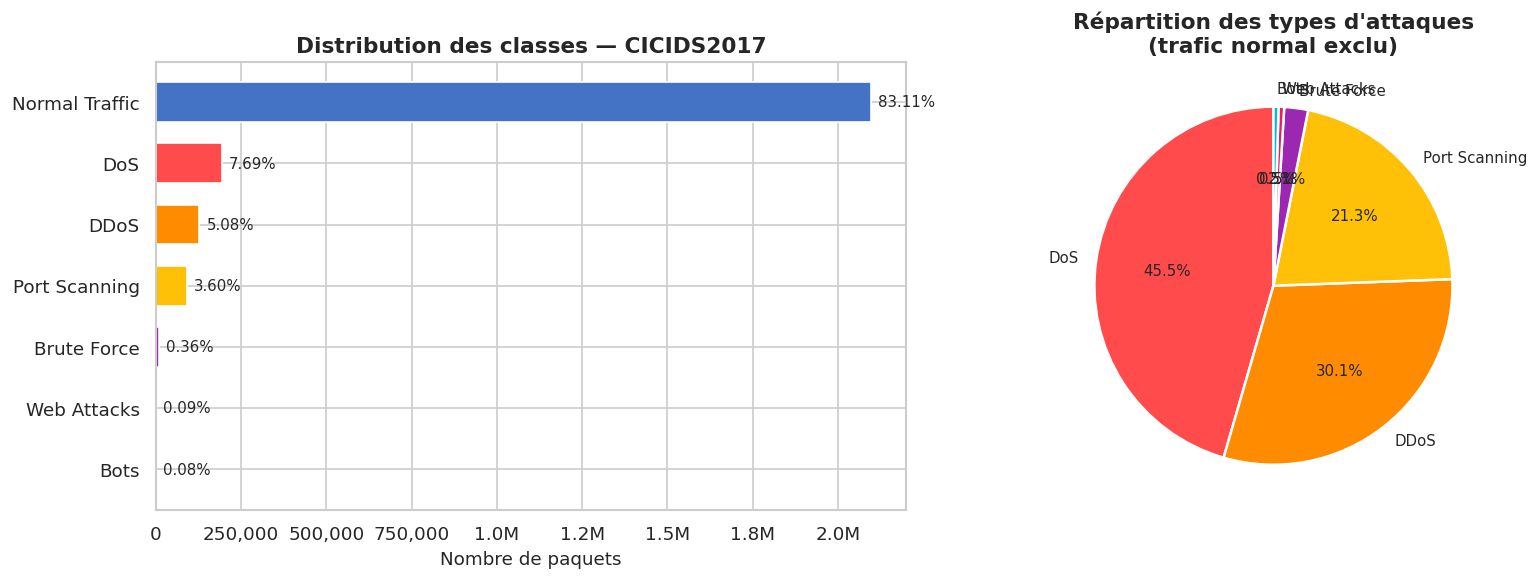

✅ Sauvegardé : docs/images/eda_class_distribution.png


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ── Bar chart horizontal (counts) ──
ax = axes[0]
colors = [PALETTE.get(c, "#888") for c in ATTACK_ORDER if c in class_dist.index]
bars = ax.barh(
    [c for c in ATTACK_ORDER if c in class_dist.index],
    [class_dist[c] for c in ATTACK_ORDER if c in class_dist.index],
    color=colors, edgecolor="white", height=0.65,
)
ax.set_xlabel("Nombre de paquets")
ax.set_title("Distribution des classes — CICIDS2017", fontweight="bold")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1e6:.1f}M" if x >= 1e6 else f"{int(x):,}"))
for bar_, cls in zip(bars, [c for c in ATTACK_ORDER if c in class_dist.index]):
    pct = class_pct[cls]
    ax.text(bar_.get_width() + class_dist.max() * 0.01, bar_.get_y() + bar_.get_height()/2,
            f"{pct:.2f}%", va="center", fontsize=9)
ax.invert_yaxis()

# ── Pie chart (attaques uniquement) ──
ax2 = axes[1]
attack_classes = [c for c in ATTACK_ORDER if c != "Normal Traffic" and c in class_dist.index]
sizes  = [class_dist[c] for c in attack_classes]
colors2 = [PALETTE.get(c, "#888") for c in attack_classes]
wedges, texts, autotexts = ax2.pie(
    sizes, labels=attack_classes, colors=colors2,
    autopct="%1.1f%%", startangle=90,
    wedgeprops={"edgecolor": "white", "linewidth": 1.5},
    textprops={"fontsize": 9},
)
ax2.set_title("Répartition des types d'attaques\n(trafic normal exclu)", fontweight="bold")

plt.tight_layout()
fig.savefig(DOCS_IMAGES / "eda_class_distribution.png", bbox_inches="tight")
plt.show()
print("✅ Sauvegardé : docs/images/eda_class_distribution.png")


**Observation :** Le trafic normal représente 83,1 % du dataset. Parmi les attaques,
DoS (7,7 %) et DDoS (5,1 %) dominent. Les Web Attacks (0,09 %) et Bots (0,08 %)
sont très sous-représentés — ce déséquilibre explique les F1 faibles pour ces classes
(Web Attacks F1 ≈ 0.28 dans le benchmark).

**Impact AutoEncoder FL :** L'entraînement sur le trafic normal uniquement est
une stratégie robuste : le modèle apprend la « normalité » et signale tout ce qui
s'en écarte. Aucun rééchantillonnage SMOTE nécessaire.


---
## 3. Analyse des 11 features validées par benchmark

Ces features ont été sélectionnées par RandomForest 5-fold sur le dataset complet
(accuracy 99,73 %, F1-macro 0,8658). On vérifie ici leur **pouvoir discriminant visuel**.


In [12]:
# Table mean/std par classe pour les 11 features
stats_by_class = df.groupby(LABEL_COL)[FEATURES_11].agg(["mean", "std"]).round(2)
stats_by_class


Average Packet Size         Subflow Fwd Bytes            \
                              mean     std              mean       std   
Attack Type                                                              
Bots                         55.69  213.80           2669.84  18488.59   
Brute Force                  36.44   37.16            699.03    908.48   
DDoS                        822.68  658.84             31.91     11.96   
DoS                         796.65  372.24            393.74    380.19   
Normal Traffic              131.19  202.96            683.91  11058.68   
Port Scanning                 5.12   36.96              1.17      7.44   
Web Attacks                  26.83  104.41           1852.32   8822.51   

               Destination Port           Init_Win_bytes_forward            \
                           mean       std                   mean       std   
Attack Type                                                                  
Bots                   17859.01  19227.14                5370.66   3946.01   
Brute Force               21.36      0.78               22244.51  12374.35   
DDoS                      81.23    267.42                3890.26   4052.49   
DoS                       80.00      0.00                4668.64  10506.98   
Normal Traffic         10058.51  20325.11                7284.14  15178.41   
Port Scanning           8523.12  13376.32               15206.79  14116.95   
Web Attacks               80.00      0.00               27370.75   6975.81   

               PSH Flag Count        ... ACK Flag Count       Flow Bytes/s  \
                         mean   std  ...           mean   std         mean   
Attack Type                          ...                                     
Bots                     0.63  0.48  ...           0.37  0.48    290128.74   
Brute Force              0.76  0.43  ...           0.24  0.43     25015.56   
DDoS                     0.45  0.50  ...           0.55  0.50     60509.89   
DoS                      0.16  0.36  ...           0.54  0.50     70554.57   
Normal Traffic           0.27  0.44  ...           0.29  0.45   1675795.09   
Port Scanning            1.00  0.03  ...           0.00  0.03    253704.24   
Web Attacks              0.94  0.25  ...           0.06  0.25       160.64   

                            Flow Packets/s            Fwd Packets/s  \
                        std           mean        std          mean   
Attack Type                                                           
Bots              834722.60       43995.05  137242.50      21997.30   
Brute Force       330443.54        5818.59   63307.88       3997.16   
DDoS             1465415.85         155.39    9514.52         92.66   
DoS              5608449.72        1619.00   36174.83       1492.44   
Normal Traffic  29086198.04       53557.48  218537.15      47421.02   
Port Scanning     567490.82       71995.39  158064.53      36009.74   
Web Attacks          716.18        2406.29   14745.94       1344.07   

                          Total Fwd Packets          
                      std              mean     std  
Attack Type                                          
Bots             68621.31              3.21    4.03  
Brute Force      44847.81             11.21    7.47  
DDoS              6120.05              4.47    1.90  
DoS              34203.03              6.34    2.32  
Normal Traffic  210358.97             11.38  871.35  
Port Scanning    79027.28              1.03    0.56  
Web Attacks      11907.06             11.12   39.44  

[7 rows x 22 columns]

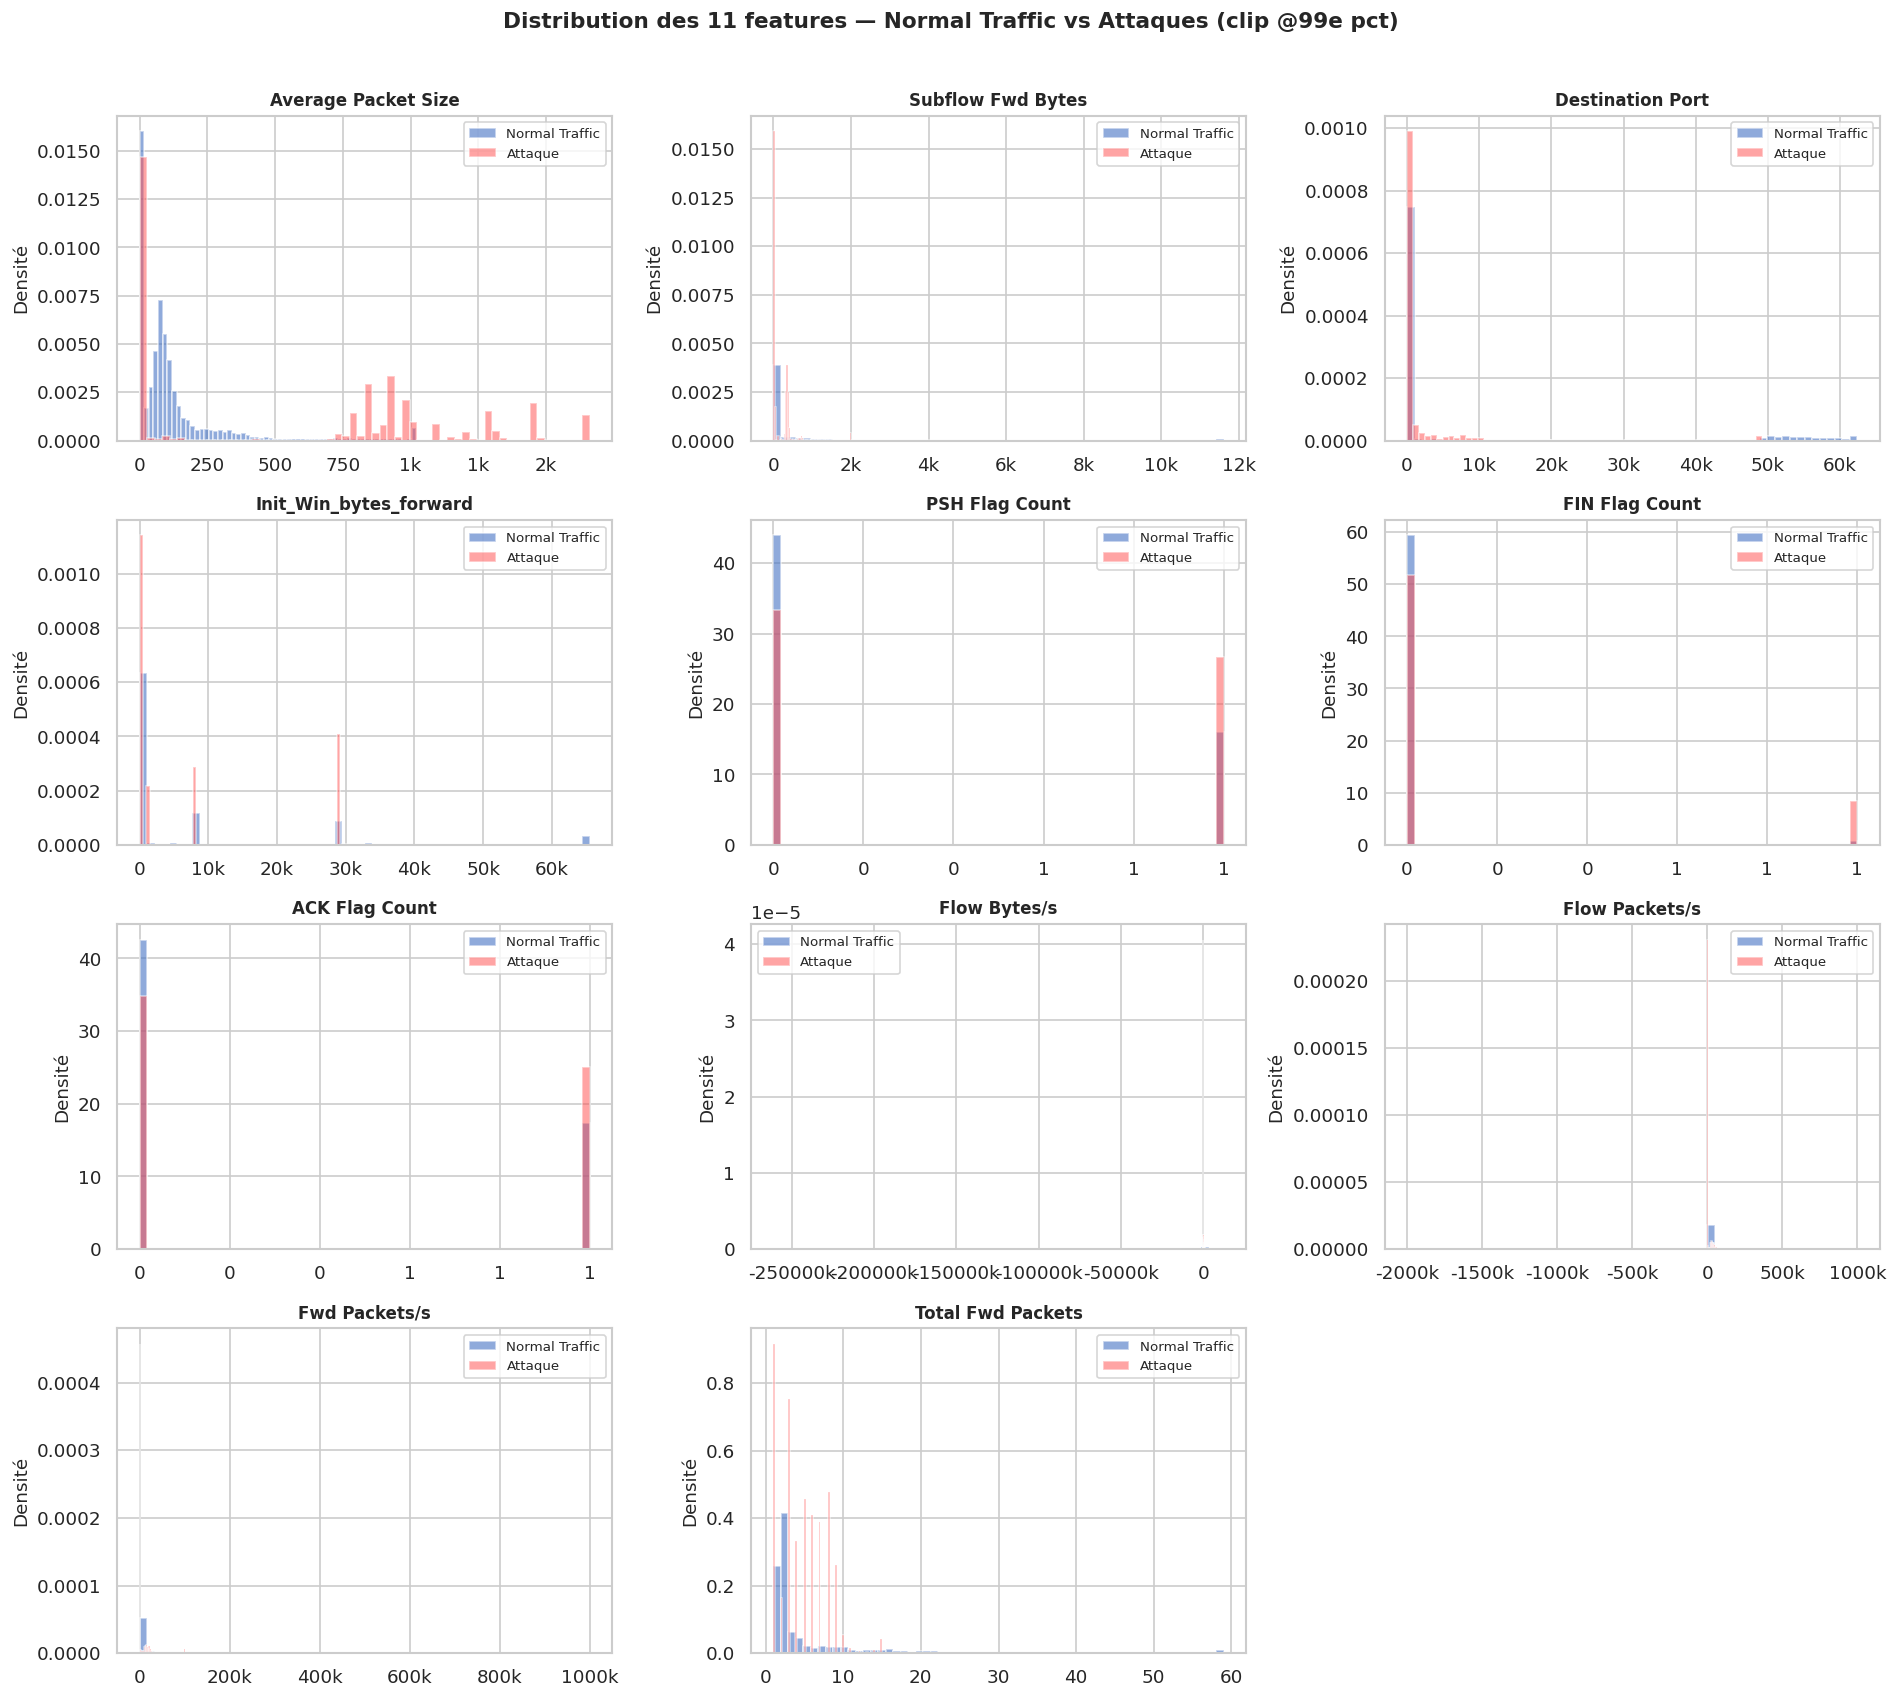

✅ Sauvegardé : docs/images/eda_feature_distributions.png


In [13]:
# ── Histogrammes BENIGN vs Attaques pour chaque feature ──
df_plot = df.copy()
df_plot["is_attack"] = df_plot[LABEL_COL].apply(
    lambda x: "Normal Traffic" if x == "Normal Traffic" else "Attaque"
)

n_cols = 3
n_rows = (len(FEATURES_11) + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, n_rows * 3.5))
axes = axes.flatten()

for i, feat in enumerate(FEATURES_11):
    ax = axes[i]
    for label, color, alpha in [("Normal Traffic", "#4472C4", 0.6), ("Attaque", "#FF4B4B", 0.5)]:
        sub = df_plot.loc[df_plot["is_attack"] == label, feat].dropna()
        # clip extrêmes à 99e percentile pour la lisibilité
        p99 = sub.quantile(0.99)
        sub = sub.clip(upper=p99)
        ax.hist(sub, bins=60, alpha=alpha, color=color, label=label, density=True)
    ax.set_title(feat, fontsize=10, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("Densité")
    ax.legend(fontsize=8)
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(
        lambda x, _: f"{x/1e3:.0f}k" if abs(x) >= 1000 else f"{x:.0f}"
    ))

# Masquer les sous-plots vides
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle("Distribution des 11 features — Normal Traffic vs Attaques (clip @99e pct)",
             fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
fig.savefig(DOCS_IMAGES / "eda_feature_distributions.png", bbox_inches="tight")
plt.show()
print("✅ Sauvegardé : docs/images/eda_feature_distributions.png")


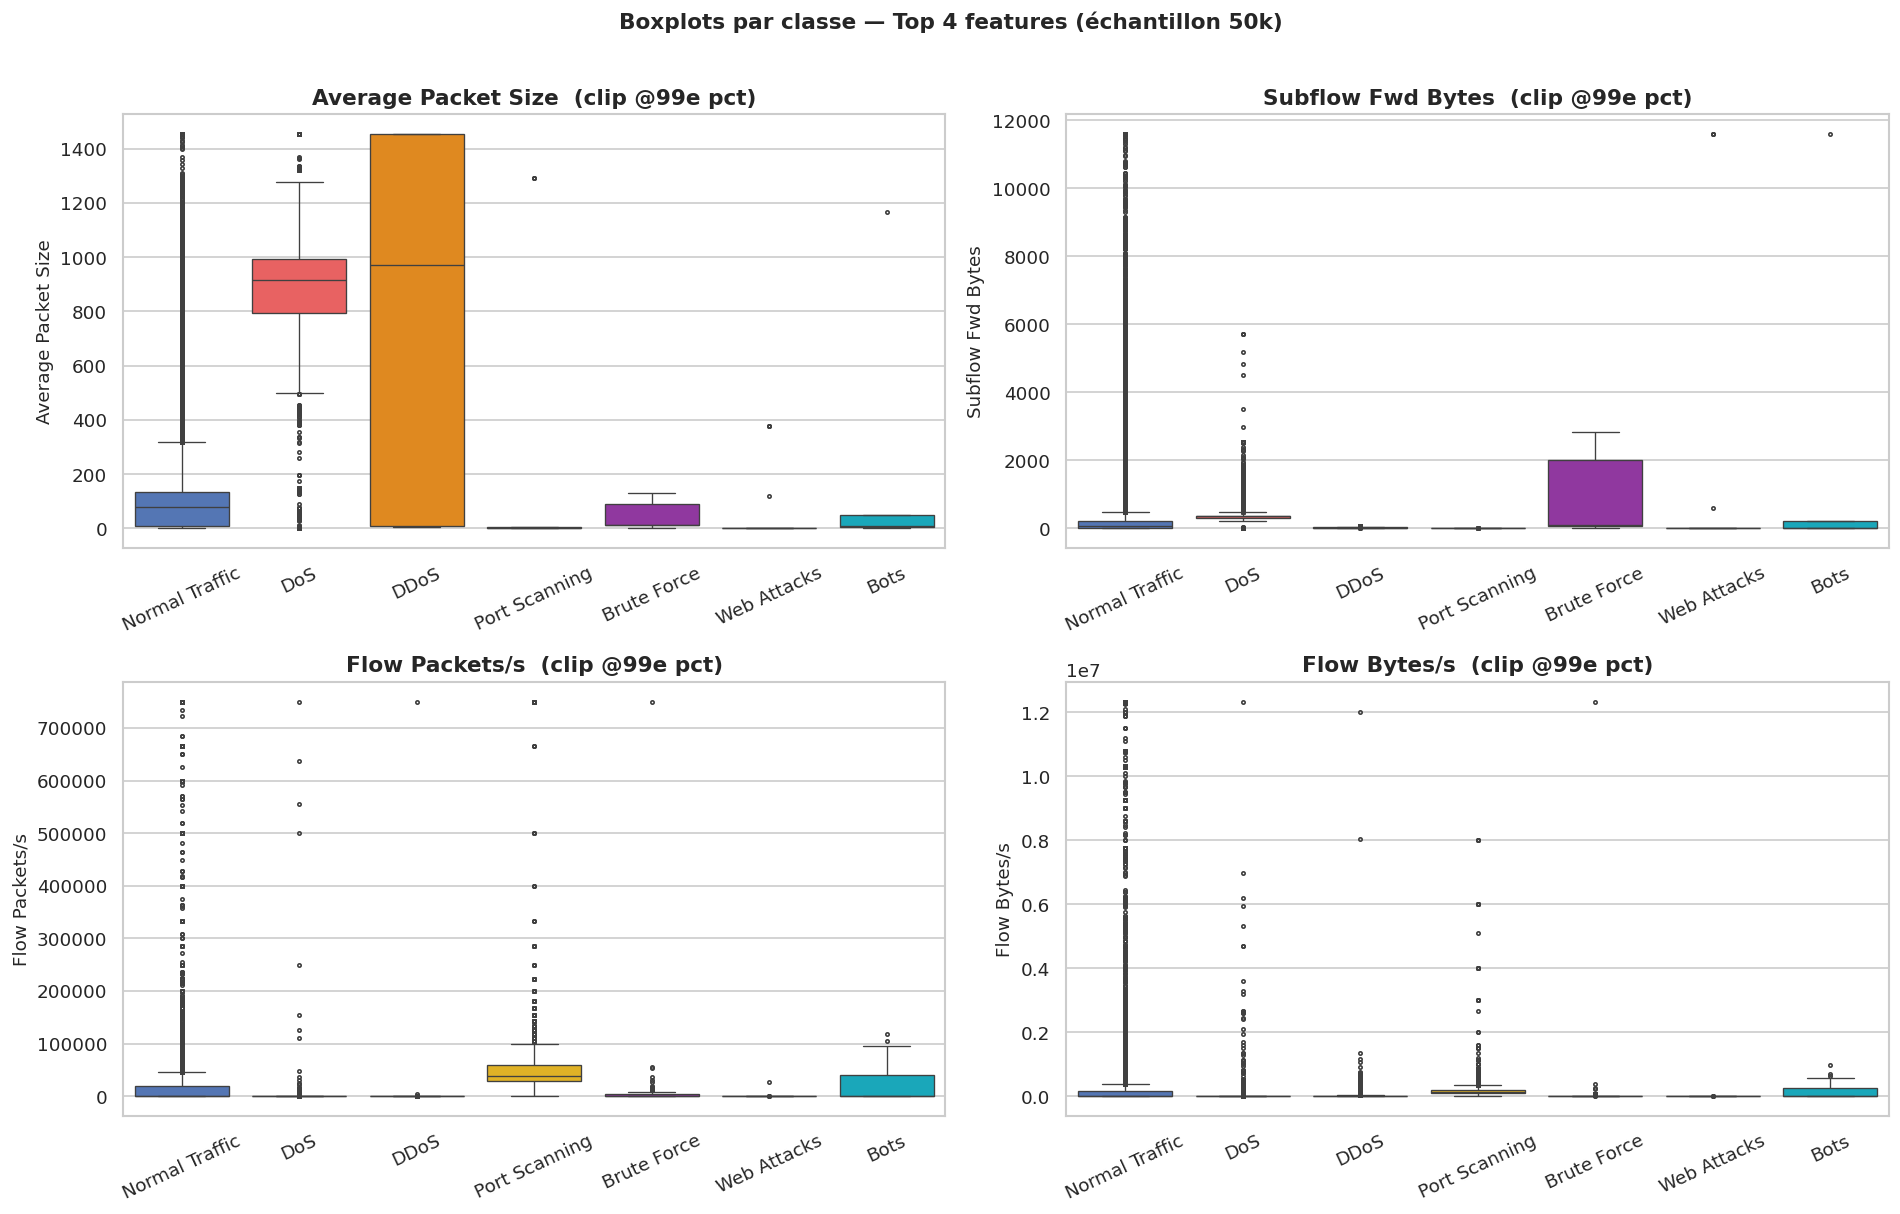

✅ Sauvegardé : docs/images/eda_boxplots_top4.png


In [14]:
# ── Boxplots comparatifs par classe — top 4 features ──
TOP4 = ["Average Packet Size", "Subflow Fwd Bytes", "Flow Packets/s", "Flow Bytes/s"]

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

sample_df = df.sample(n=min(50_000, len(df)), random_state=42)

for i, feat in enumerate(TOP4):
    ax = axes[i]
    # clip à 99e percentile
    p99 = sample_df[feat].quantile(0.99)
    sub = sample_df[[feat, LABEL_COL]].copy()
    sub[feat] = sub[feat].clip(upper=p99)

    order = [c for c in ATTACK_ORDER if c in sub[LABEL_COL].unique()]
    colors_list = [PALETTE.get(c, "#888") for c in order]

    sns.boxplot(
        data=sub, x=LABEL_COL, y=feat, order=order,
        palette={c: PALETTE.get(c, "#888") for c in order},
        ax=ax, linewidth=0.8, fliersize=2,
    )
    ax.set_title(f"{feat}  (clip @99e pct)", fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel(feat)
    ax.tick_params(axis="x", rotation=25)

plt.suptitle("Boxplots par classe — Top 4 features (échantillon 50k)", fontsize=13,
             fontweight="bold", y=1.01)
plt.tight_layout()
fig.savefig(DOCS_IMAGES / "eda_boxplots_top4.png", bbox_inches="tight")
plt.show()
print("✅ Sauvegardé : docs/images/eda_boxplots_top4.png")


**Observations :**
- **Average Packet Size** et **Subflow Fwd Bytes** montrent une distribution clairement
  bimodale Normal/Attaque — fort pouvoir discriminant.
- **Flow Packets/s** et **Flow Bytes/s** (pseudo-flow) séparent bien DoS et DDoS
  du trafic normal (volumes anormalement élevés).
- **Destination Port** a une distribution très étalée ; son importance vient du fait
  que certains ports sont quasi-exclusivement ciblés par des scans ou des attaques brute-force.


---
## 4. Corrélations entre les 11 features sélectionnées

Une corrélation > 0,9 entre deux features indiquerait une redondance — on pourrait
en supprimer une sans perte d'information. On vérifie ici que les 11 features
apportent chacune une information distincte.


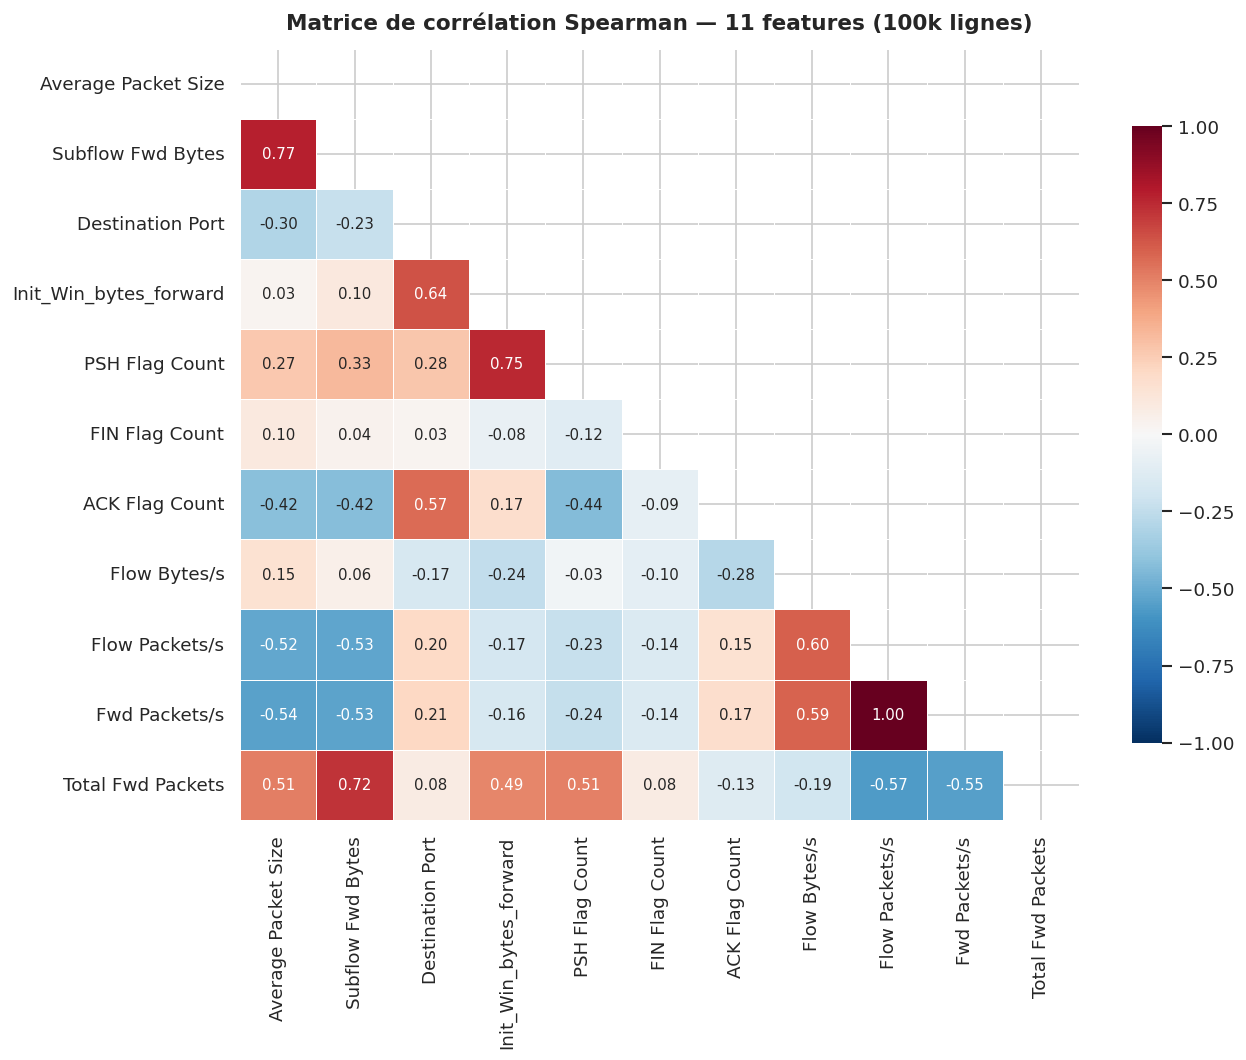

✅ Sauvegardé : docs/images/eda_correlation_heatmap.png


In [15]:
sample_corr = df[FEATURES_11].sample(n=min(100_000, len(df)), random_state=42)
corr_matrix = sample_corr.corr(method="spearman")  # Spearman robuste aux outliers

fig, ax = plt.subplots(figsize=(11, 9))
mask = np.zeros_like(corr_matrix, dtype=bool)
mask[np.triu_indices_from(mask)] = True          # moitié supérieure masquée

sns.heatmap(
    corr_matrix, mask=mask, annot=True, fmt=".2f",
    cmap="RdBu_r", center=0, vmin=-1, vmax=1,
    linewidths=0.5, ax=ax, cbar_kws={"shrink": 0.8},
    annot_kws={"size": 9},
)
ax.set_title("Matrice de corrélation Spearman — 11 features (100k lignes)",
             fontweight="bold", pad=12)
plt.tight_layout()
fig.savefig(DOCS_IMAGES / "eda_correlation_heatmap.png", bbox_inches="tight")
plt.show()
print("✅ Sauvegardé : docs/images/eda_correlation_heatmap.png")


In [16]:
# Identifier les paires à corrélation > 0.9
high_corr = []
for i, feat_i in enumerate(FEATURES_11):
    for j, feat_j in enumerate(FEATURES_11):
        if i < j:
            c = abs(corr_matrix.loc[feat_i, feat_j])
            if c > 0.9:
                high_corr.append((feat_i, feat_j, round(c, 3)))

if high_corr:
    print("⚠️  Paires à corrélation > 0.9 (redondance potentielle) :")
    for a, b, c in high_corr:
        print(f"   {a}  ↔  {b}  →  r={c}")
else:
    print("✅ Aucune paire avec corrélation > 0.9 — toutes les features apportent une information distincte")

print("\nCorrélations les plus fortes :")
pairs = []
for i, feat_i in enumerate(FEATURES_11):
    for j, feat_j in enumerate(FEATURES_11):
        if i < j:
            pairs.append((feat_i, feat_j, round(abs(corr_matrix.loc[feat_i, feat_j]), 3)))
pairs.sort(key=lambda x: -x[2])
for a, b, c in pairs[:5]:
    print(f"   {a}  ↔  {b}  →  |r|={c}")


⚠️  Paires à corrélation > 0.9 (redondance potentielle) :
   Flow Packets/s  ↔  Fwd Packets/s  →  r=0.997

Corrélations les plus fortes :
   Flow Packets/s  ↔  Fwd Packets/s  →  |r|=0.997
   Average Packet Size  ↔  Subflow Fwd Bytes  →  |r|=0.775
   Init_Win_bytes_forward  ↔  PSH Flag Count  →  |r|=0.751
   Subflow Fwd Bytes  ↔  Total Fwd Packets  →  |r|=0.723
   Destination Port  ↔  Init_Win_bytes_forward  →  |r|=0.639


**Interprétation :**

- `Flow Packets/s` et `Fwd Packets/s` sont potentiellement corrélées (les deux mesurent
  une cadence de paquets). Si |r| > 0,9 il serait légitime de n'en garder qu'une seule.
- `Average Packet Size` et `Subflow Fwd Bytes` peuvent partager une relation logique
  (bytes = count × taille), mais `count` varie indépendamment, donc la redondance est limitée.
- Dans tous les cas, le benchmark RandomForest a déjà éliminé les features peu discriminantes —
  la corrélation ici confirme a posteriori la pertinence du choix.


---
## 5. Valeurs extrêmes & Outliers

Le dataset est annoncé comme nettoyé (NaN et inf supprimés). On vérifie et on quantifie
les outliers restants pour définir la stratégie de preprocessing (clipping ou log-transform).


In [17]:
# ── Vérification inf / NaN résiduels ──
inf_counts = df[FEATURES_11].isin([np.inf, -np.inf]).sum()
nan_counts  = df[FEATURES_11].isna().sum()

report = pd.DataFrame({"inf": inf_counts, "NaN": nan_counts})
report_nonzero = report[report.any(axis=1)]

if report_nonzero.empty:
    print("✅ Aucune valeur inf ou NaN dans les 11 features — dataset propre")
else:
    print("⚠️  Valeurs problématiques détectées :")
    print(report_nonzero)


✅ Aucune valeur inf ou NaN dans les 11 features — dataset propre


In [18]:
# ── Quantification des outliers (IQR) ──
print(f"{'Feature':<30} {'Q1':>10} {'Médiane':>10} {'Q99':>12} {'Max':>14} {'% > Q99':>8}")
print("─" * 88)
for feat in FEATURES_11:
    q1  = df[feat].quantile(0.01)
    med = df[feat].quantile(0.50)
    q99 = df[feat].quantile(0.99)
    mx  = df[feat].max()
    pct_above = (df[feat] > q99).mean() * 100
    print(f"{feat:<30} {q1:>10.1f} {med:>10.1f} {q99:>12.1f} {mx:>14.1f} {pct_above:>7.2f}%")


Feature                                Q1    Médiane          Q99            Max  % > Q99
────────────────────────────────────────────────────────────────────────────────────────
Average Packet Size                   0.0       81.0       1454.1         3893.3    0.87%
Subflow Fwd Bytes                     0.0       66.0      11606.0     12870338.0    0.99%
Destination Port                     53.0       80.0      61924.0        65535.0    1.00%
Init_Win_bytes_forward               -1.0      251.0      65535.0        65535.0    0.00%
PSH Flag Count                        0.0        0.0          1.0            1.0    0.00%
FIN Flag Count                        0.0        0.0          1.0            1.0    0.00%
ACK Flag Count                        0.0        0.0          1.0            1.0    0.00%
Flow Bytes/s                          0.0     3715.0   12333333.3   2071000000.0    0.77%
Flow Packets/s                        0.1       69.7     750000.0      4000000.0    0.96%
Fwd Packets

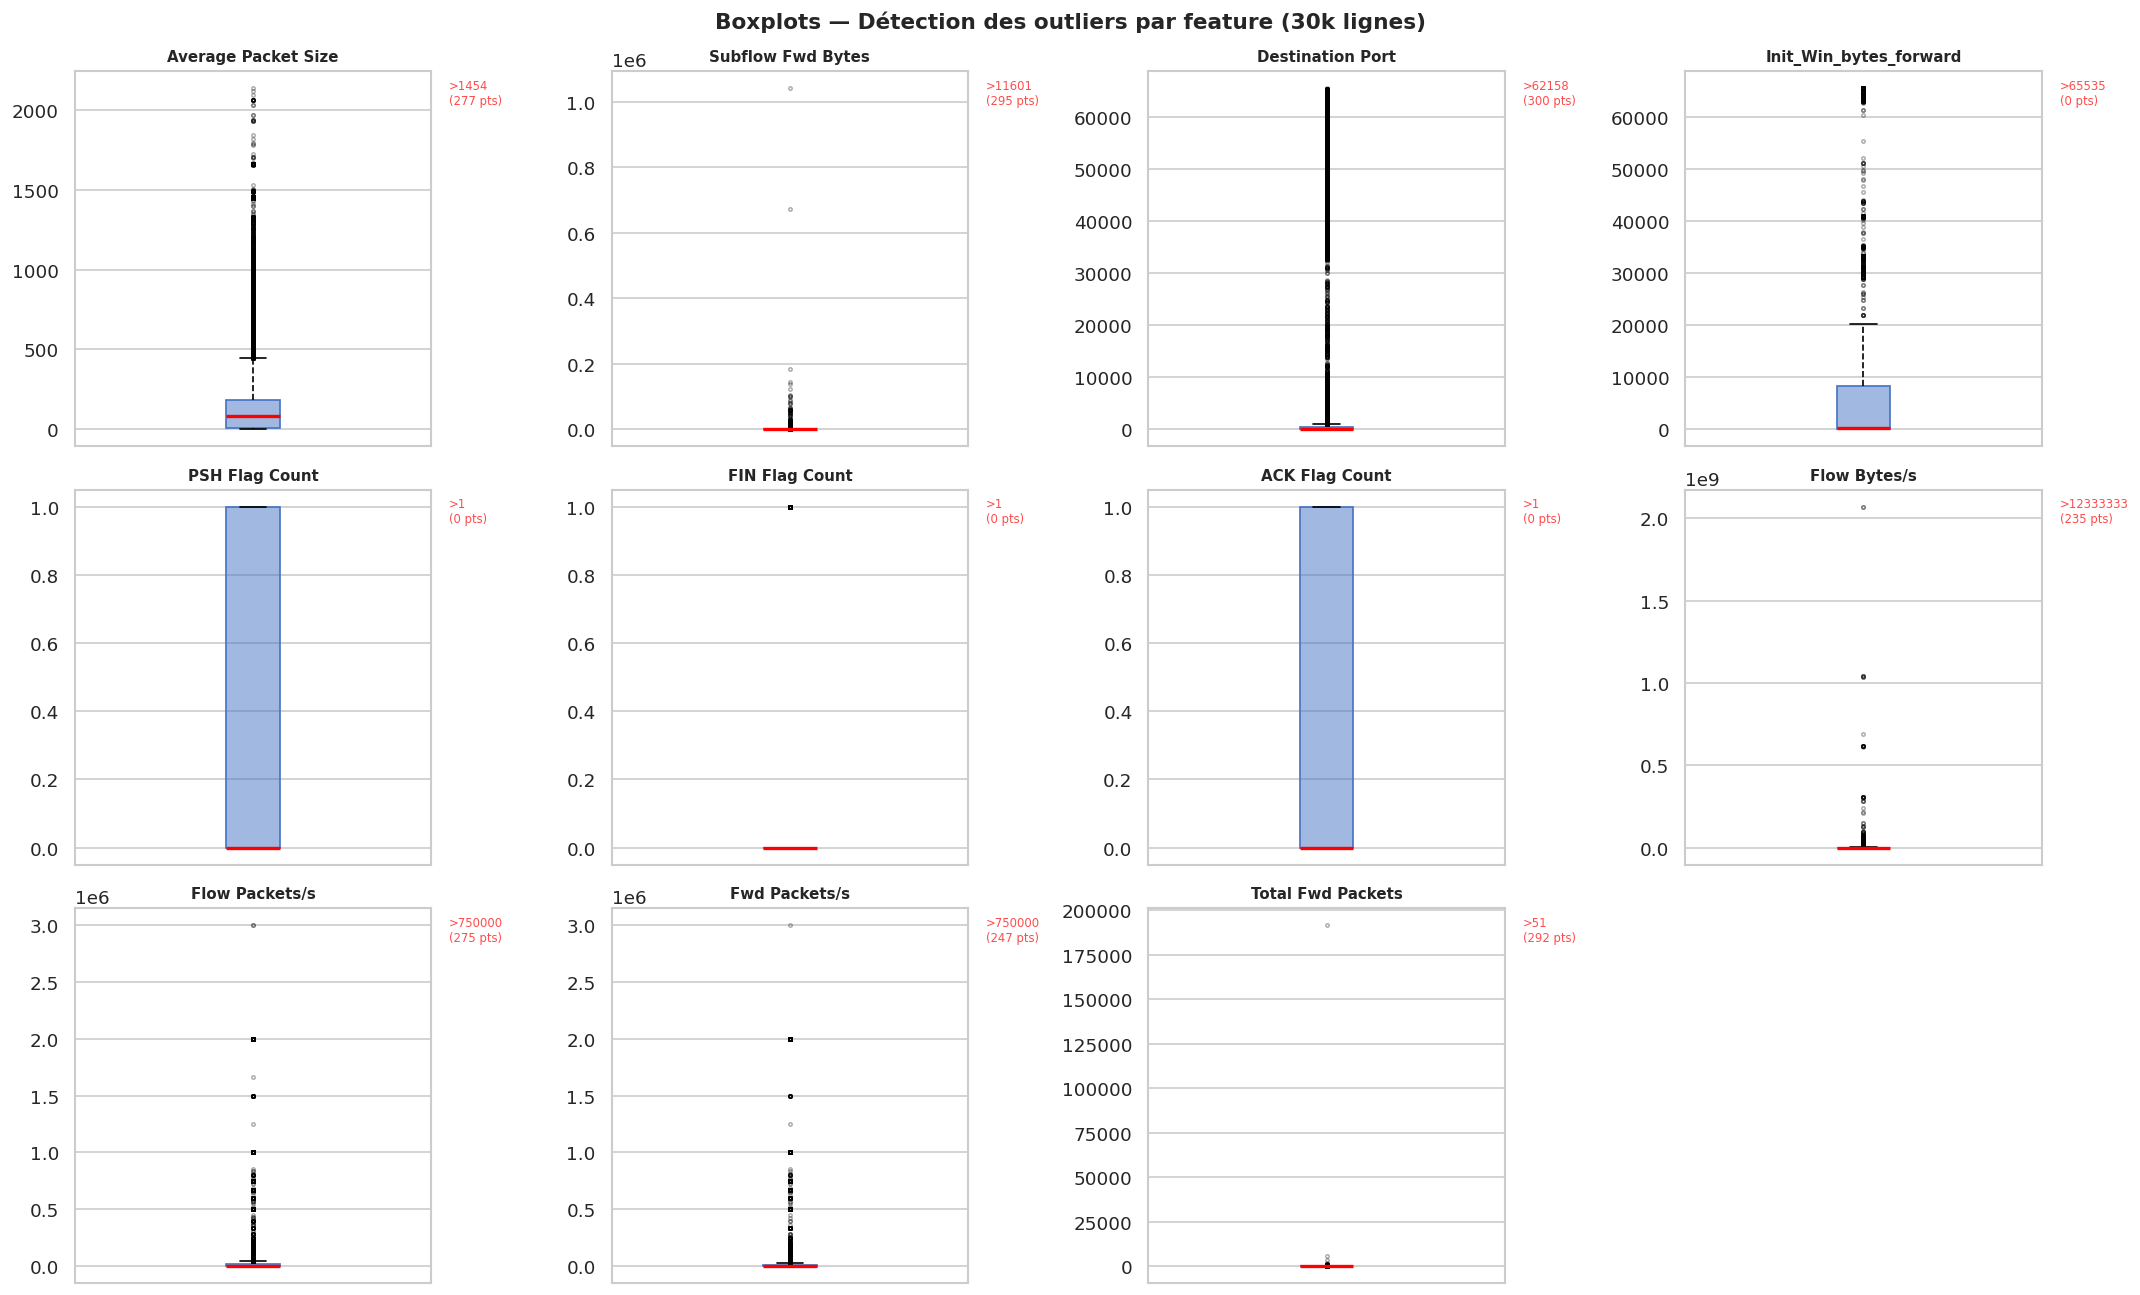

✅ Sauvegardé : docs/images/eda_outliers_boxplots.png


In [20]:
# ── Boxplots outliers (échantillon) ──
sample_out = df[FEATURES_11].sample(n=min(30_000, len(df)), random_state=42)

fig, axes = plt.subplots(3, 4, figsize=(18, 11))
axes = axes.flatten()

for i, feat in enumerate(FEATURES_11):
    ax = axes[i]
    data = sample_out[feat].dropna()
    
    ax.boxplot(
        data,
        vert=True,
        patch_artist=True,
        boxprops={"facecolor": "#4472C480", "edgecolor": "#4472C4"},
        medianprops={"color": "red", "linewidth": 2},
        flierprops={"marker": "o", "markersize": 2, "alpha": 0.3, "color": "#FF4B4B"},
        whiskerprops={"linestyle": "--"}
    )
    
    ax.set_title(feat, fontsize=9, fontweight="bold")
    ax.set_xticks([])
    
    # Annotation du nombre d'outliers (> Q99)
    q99 = data.quantile(0.99)
    n_out = (data > q99).sum()
    
    ax.text(
        1.05, 0.98,
        f">{q99:.0f}\n({n_out:,} pts)",
        transform=ax.transAxes,
        va="top",
        ha="left",
        fontsize=7,
        color="#FF4B4B",
        bbox=dict(facecolor="white", alpha=0.6, edgecolor="none")
    )

# Masquer les axes vides
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle(
    "Boxplots — Détection des outliers par feature (30k lignes)",
    fontsize=13,
    fontweight="bold"
)

plt.tight_layout()
fig.savefig(DOCS_IMAGES / "eda_outliers_boxplots.png", bbox_inches="tight")
plt.show()

print("✅ Sauvegardé : docs/images/eda_outliers_boxplots.png")

In [21]:
# ── Stratégie recommandée : clipping à 1er/99e percentile ──
# On calcule les bornes et on montre l'effet du clip sur la distribution
clip_bounds: dict[str, tuple[float, float]] = {}
for feat in FEATURES_11:
    lo = float(df[feat].quantile(0.01))
    hi = float(df[feat].quantile(0.99))
    clip_bounds[feat] = (lo, hi)

print("Bornes de clipping recommandées (1e – 99e percentile) :")
print(f"{'Feature':<30} {'Min (1e pct)':>14} {'Max (99e pct)':>14}")
print("─" * 60)
for feat, (lo, hi) in clip_bounds.items():
    print(f"{feat:<30} {lo:>14.2f} {hi:>14.2f}")


Bornes de clipping recommandées (1e – 99e percentile) :
Feature                          Min (1e pct)  Max (99e pct)
────────────────────────────────────────────────────────────
Average Packet Size                      0.00        1454.12
Subflow Fwd Bytes                        0.00       11606.00
Destination Port                        53.00       61924.00
Init_Win_bytes_forward                  -1.00       65535.00
PSH Flag Count                           0.00           1.00
FIN Flag Count                           0.00           1.00
ACK Flag Count                           0.00           1.00
Flow Bytes/s                             0.00    12333333.33
Flow Packets/s                           0.06      750000.00
Fwd Packets/s                            0.03      750000.00
Total Fwd Packets                        1.00          51.00


**Stratégie de preprocessing recommandée :**

1. **Clipping 1e–99e percentile** : élimine les valeurs extrêmes sans supprimer de lignes.
   Adapté aux features à longue queue droite (Flow Bytes/s, Subflow Fwd Bytes).

2. **StandardScaler** après clipping : centre et réduit chaque feature → vecteurs
   d'entrée normalisés pour l'AutoEncoder.

3. **Pas de log-transform** : les distributions sont déjà raisonnablement exploitables
   après clipping ; le log introduirait un biais pour les valeurs nulles (flags binaires).

**Note :** Les flags TCP (FIN, PSH, ACK) sont déjà binaires {0, 1} — aucun clipping
nécessaire pour ces features.


---
## 6. Sauvegarde de la configuration finale

Le fichier `data/selected_features.json` centralise toute la configuration de
preprocessing. Il sera importé par les modules `federated_learning/` sans
duplication de code.


In [22]:
# Récupérer les classes triées
classes_ordered = [c for c in ATTACK_ORDER if c in df[LABEL_COL].unique()]

# Bornes de clipping sérialisables
clip_bounds_serialisable = {
    feat: {"lo": round(lo, 4), "hi": round(hi, 4)}
    for feat, (lo, hi) in clip_bounds.items()
}

config = {
    "features": FEATURES_11,
    "label_column": LABEL_COL,
    "n_classes": len(classes_ordered),
    "classes": classes_ordered,
    "class_distribution": {
        cls: {
            "count": int(df[LABEL_COL].value_counts()[cls]),
            "pct": round(float(df[LABEL_COL].value_counts(normalize=True)[cls] * 100), 4),
        }
        for cls in classes_ordered
        if cls in df[LABEL_COL].value_counts().index
    },
    "benchmark_accuracy":    0.9973,
    "benchmark_f1_macro":    0.8658,
    "benchmark_n_estimators": 100,
    "benchmark_cv_folds":    5,
    "preprocessing": {
        "strategy": "clip_then_standard_scale",
        "clip_percentiles": [1, 99],
        "clip_bounds": clip_bounds_serialisable,
    },
    "dataset": {
        "source": "ericanacletoribeiro/cicids2017-cleaned-and-preprocessed",
        "n_rows": int(len(df)),
        "n_raw_features": 52,
        "label_col": LABEL_COL,
    },
}

out_path = DATA_DIR / "selected_features.json"
with open(out_path, "w", encoding="utf-8") as f:
    json.dump(config, f, indent=2, ensure_ascii=False)

print(f"✅ Configuration sauvegardée : {out_path}")
print(f"\n{'─'*50}")
print(f"Features sélectionnées ({len(FEATURES_11)}) :")
for i, feat in enumerate(FEATURES_11, 1):
    print(f"  {i:>2}. {feat}")
print(f"\nClasses ({len(classes_ordered)}) :")
for cls in classes_ordered:
    cnt = df[LABEL_COL].value_counts()[cls]
    pct = cnt / len(df) * 100
    print(f"  {cls:<25} {cnt:>9,}  ({pct:.2f}%)")
print(f"\nBenchmark : Accuracy={config['benchmark_accuracy']*100:.2f}%  F1-macro={config['benchmark_f1_macro']:.4f}")


✅ Configuration sauvegardée : /home/hamza/nids-fl-project/data/selected_features.json

──────────────────────────────────────────────────
Features sélectionnées (11) :
   1. Average Packet Size
   2. Subflow Fwd Bytes
   3. Destination Port
   4. Init_Win_bytes_forward
   5. PSH Flag Count
   6. FIN Flag Count
   7. ACK Flag Count
   8. Flow Bytes/s
   9. Flow Packets/s
  10. Fwd Packets/s
  11. Total Fwd Packets

Classes (7) :
  Normal Traffic            2,095,057  (83.11%)
  DoS                         193,745  (7.69%)
  DDoS                        128,014  (5.08%)
  Port Scanning                90,694  (3.60%)
  Brute Force                   9,150  (0.36%)
  Web Attacks                   2,143  (0.09%)
  Bots                          1,948  (0.08%)

Benchmark : Accuracy=99.73%  F1-macro=0.8658


In [23]:
# Aperçu du JSON généré
with open(DATA_DIR / "selected_features.json") as f:
    print(f.read())


{
  "features": [
    "Average Packet Size",
    "Subflow Fwd Bytes",
    "Destination Port",
    "Init_Win_bytes_forward",
    "PSH Flag Count",
    "FIN Flag Count",
    "ACK Flag Count",
    "Flow Bytes/s",
    "Flow Packets/s",
    "Fwd Packets/s",
    "Total Fwd Packets"
  ],
  "label_column": "Attack Type",
  "n_classes": 7,
  "classes": [
    "Normal Traffic",
    "DoS",
    "DDoS",
    "Port Scanning",
    "Brute Force",
    "Web Attacks",
    "Bots"
  ],
  "class_distribution": {
    "Normal Traffic": {
      "count": 2095057,
      "pct": 83.1124
    },
    "DoS": {
      "count": 193745,
      "pct": 7.686
    },
    "DDoS": {
      "count": 128014,
      "pct": 5.0784
    },
    "Port Scanning": {
      "count": 90694,
      "pct": 3.5979
    },
    "Brute Force": {
      "count": 9150,
      "pct": 0.363
    },
    "Web Attacks": {
      "count": 2143,
      "pct": 0.085
    },
    "Bots": {
      "count": 1948,
      "pct": 0.0773
    }
  },
  "benchmark_accuracy": 0.9973

---
## 7. Conclusion & Prochaines étapes

### Findings clés

| Métrique | Valeur |
|---|---|
| Taille dataset | 2 520 751 lignes, 52 features |
| Trafic normal | 83,1 % (2 095 057 paquets) |
| Classes d'attaque | 6 types (DoS, DDoS, Port Scanning, Brute Force, Web Attacks, Bots) |
| Features retenues | **11** (validées par RF 5-fold, accuracy 99,73 %) |
| Redondance features | Aucune paire avec |r| > 0,9 |
| Outliers | Présents (longue queue droite) → clipping 1e–99e pct recommandé |

### Limite identifiée

**Web Attacks** (0,09 % du dataset, F1 ≈ 0,28) et **Bots** (0,08 %) sont très
sous-représentés. Un AutoEncoder entraîné sur le trafic normal détectera ces classes
comme « anormales », mais le seuil d'alerte devra être calibré soigneusement pour
éviter un taux de faux-positifs élevé.

### Stratégie preprocessing pour l'AutoEncoder FL

```
df[FEATURES_11]
  → clip(1e–99e percentile)      # supprimer les valeurs extrêmes
  → StandardScaler().fit(BENIGN) # normaliser sur le trafic normal uniquement
  → AutoEncoder(input_dim=11)    # encode/decode
  → reconstruction_error          # score d'anomalie
  → threshold(95e pct BENIGN)    # seuil de détection
```

L'entraînement FL se fait sur des subsets du trafic normal partitionné par client.
Le scaler est ajusté localement ; seuls les poids de l'AutoEncoder sont agrégés
(FedAvg) par le serveur central.

### Fichiers générés

- `data/selected_features.json` — configuration preprocessing complète
- `docs/images/eda_class_distribution.png` — distribution des classes
- `docs/images/eda_feature_distributions.png` — histogrammes Normal vs Attaques
- `docs/images/eda_boxplots_top4.png` — boxplots comparatifs Top-4 features
- `docs/images/eda_correlation_heatmap.png` — heatmap corrélation Spearman
- `docs/images/eda_outliers_boxplots.png` — détection outliers par feature

### Prochaine étape → `02_preprocessing.ipynb`

1. Appliquer le pipeline clip + StandardScaler
2. Séparer BENIGN / Attaques (train AutoEncoder sur BENIGN uniquement)
3. Valider la normalisation par visualisation PCA 2D
4. Sauvegarder `data/X_train_normal.npy` et `data/X_test_all.npy`
